In [1]:
import utide
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pinner2026_jpo_code
import pinner2026_jpo_code.constants
import pinner2026_jpo_code.spectra

C:\Users\opinner\Desktop\Python\pinner2026_JPO_code\.venv\Lib\site-packages\numpy\lib\_format_impl.py:838: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  array = pickle.load(fp, **pickle_kwargs)


In [2]:
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"
DERIVED_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "derived"

In [3]:
velocity = pd.read_csv(INTERIM_DATA_DIR / "velo_at_C.csv")
velocity = velocity.set_index(pd.to_datetime(velocity["time_2350"]).dt.round("min"))
velocity = velocity.drop("time_2350", axis="columns")
velocity["2350"] = velocity["2350"].apply(lambda x: complex(x))

In [4]:
velocity.head()

,2350
time_2350,
2017-01-26 11:50:00,-0.0086+0.0537j
2017-01-26 13:50:00,-0.0475+0.0206j
2017-01-26 15:50:00,-0.0440-0.0151j
2017-01-26 17:50:00,-0.0473-0.0209j
2017-01-26 19:50:00,0.0045+0.0436j


In [5]:
CONSTITUENTS = pinner2026_jpo_code.constants.get_tidal_frequencies_in_hours(tide_type="padman")
constit = [constituent.upper() for constituent in CONSTITUENTS.keys()]
constit.extend(["M3", "M4", "M6", "S4", "MSF", "SA"])
print(constit)

['M2', 'S2', 'N2', 'K2', 'K1', 'O1', 'P1', 'Q1', 'MF', 'MM', 'M3', 'M4', 'M6', 'S4', 'MSF', 'SA']


In [6]:
coef = utide.solve(
    t=velocity.index,
    u=np.real(velocity["2350"].to_numpy()),
    v=np.imag(velocity["2350"].to_numpy()),
    lat=-70.67,
    trend=True,
    nodal=True,
    constit=constit,
    method="robust",
    conf_int="MC",
    verbose=True,
)

solve: matrix prep ... solution ... done.


The amplitudes and phases from the fit are now in the `coef` data structure (a Bunch), which can be used directly in the `reconstruct` function to generate a hindcast or forecast of the tides at the times specified in the `time` array.

In [7]:
print(coef.keys())

dict_keys(['name', 'aux', 'nR', 'nNR', 'nI', 'rf', 'weights', 'Lsmaj', 'Lsmin', 'theta', 'g', 'umean', 'vmean', 'uslope', 'vslope', 'g_ci', 'Lsmaj_ci', 'Lsmin_ci', 'theta_ci', 'diagn', 'PE', 'SNR'])


In [8]:
tide = utide.reconstruct(velocity.index, coef, verbose=True)

prep/calcs ... done.


The output from the reconstruction is also a Bunch:

In [9]:
print(tide.keys())

dict_keys(['t_in', 'epoch', 'constit', 'min_SNR', 'min_PE', 't_mpl', 'u', 'v'])


In [10]:
t = velocity.index.to_pydatetime()
v = np.imag(velocity["2350"].to_numpy())
residual = velocity["2350"] - (tide.u + 1j * tide.v)

In [11]:
tide

{'t_in': DatetimeIndex(['2017-01-26 11:50:00', '2017-01-26 13:50:00',
                '2017-01-26 15:50:00', '2017-01-26 17:50:00',
                '2017-01-26 19:50:00', '2017-01-26 21:50:00',
                '2017-01-26 23:50:00', '2017-01-27 01:50:00',
                '2017-01-27 03:50:00', '2017-01-27 05:50:00',
                ...
                '2019-01-28 15:50:00', '2019-01-28 17:50:00',
                '2019-01-28 19:50:00', '2019-01-28 21:50:00',
                '2019-01-28 23:50:00', '2019-01-29 01:50:00',
                '2019-01-29 03:50:00', '2019-01-29 05:50:00',
                '2019-01-29 07:50:00', '2019-01-29 09:50:00'],
               dtype='datetime64[us]', name='time_2350', length=8796, freq=None),
 'epoch': None,
 'constit': None,
 'min_SNR': 2,
 'min_PE': 0,
 't_mpl': array([736355.49305556, 736355.57638889, 736355.65972222, ...,
        737088.24305556, 737088.32638889, 737088.40972222], shape=(8796,)),
 'u': array([0.03697245, 0.02422346, 0.01082585, ..., 0.0

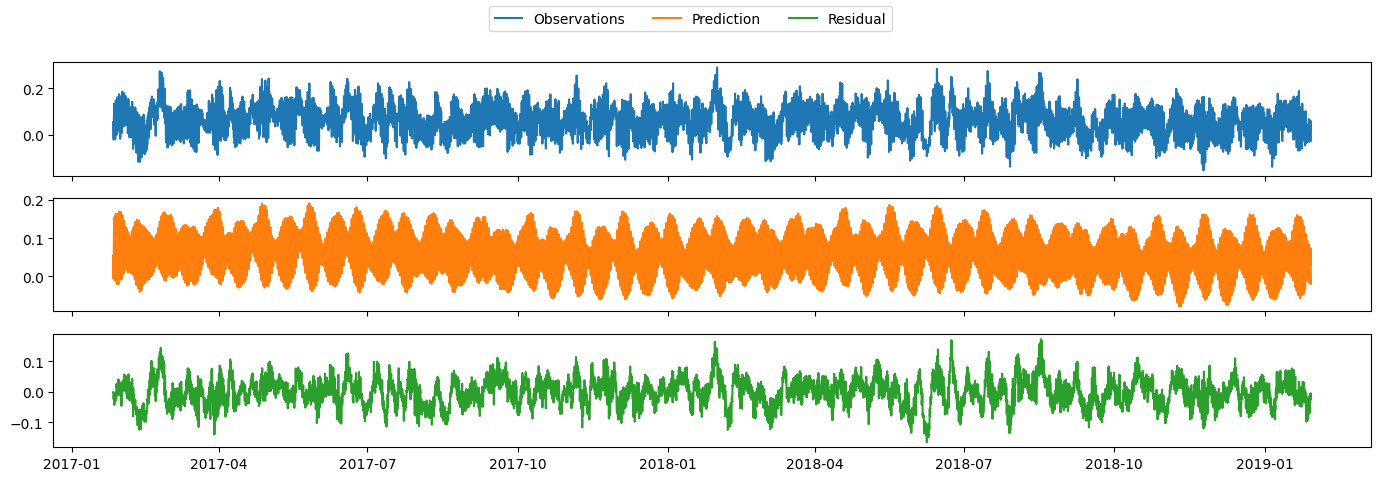

In [12]:
fig, (ax0, ax1, ax2) = plt.subplots(figsize=(17, 5), nrows=3, sharex=True)

ax0.plot(t, v, label="Observations", color="C0")
ax1.plot(t, tide.v, label="Prediction", color="C1")
ax2.plot(t, np.imag(residual.to_numpy()), label="Residual", color="C2")
fig.legend(ncol=3, loc="upper center");

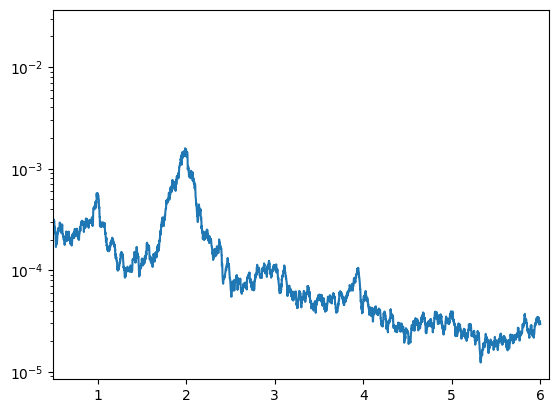

In [13]:
freq, PSD = pinner2026_jpo_code.spectra.total_multitaper(residual.to_numpy(), dt=1 / 12, P=12)
fig, ax = plt.subplots(1)
ax.set_xlim(0.5, 6.1)
ax.semilogy(freq, PSD)

In [14]:
try:
    coef = utide.solve(
        t=residual.index,
        u=np.real(residual.to_numpy()),
        v=np.imag(residual.to_numpy()),
        lat=-70.67,
        constit="auto",
        method="robust",
        conf_int="MC",
        verbose=True,
    )
except np.linalg.LinAlgError as e:
    print(e)

solve: matrix prep ... solution ... SVD did not converge


In [15]:
tidal_velocity_at_C = pd.DataFrame(
    index=velocity.index, data={"tidal_uv [m/s]": tide.u + 1j * tide.v}
)
tidal_velocity_at_C.head()

,tidal_uv [m/s]
time_2350,
2017-01-26 11:50:00,0.036972+0.054559j
2017-01-26 13:50:00,0.024223+0.021475j
2017-01-26 15:50:00,0.010826-0.006188j
2017-01-26 17:50:00,0.003150+0.003137j
2017-01-26 19:50:00,0.002636+0.059638j


In [16]:
tidal_velocity_at_C.to_csv(INTERIM_DATA_DIR / "tidal_velocity_at_C.csv")

In [33]:
# addition of 48 hours creates centered labels of the time intervals as resample labels the left edge by default
tidal_strength = (
    pd.Series(index=velocity.index + pd.Timedelta(hours=48), data=tide.u).abs().resample("5D").max()
    + 1j
    * pd.Series(index=velocity.index + pd.Timedelta(hours=48), data=tide.v)
    .abs()
    .resample("5D")
    .max()
).abs()
tidal_strength.head()

time_2350
2017-01-28    0.177676
2017-02-02    0.175672
2017-02-07    0.155323
2017-02-12    0.153327
2017-02-17    0.131042
Freq: 5D, dtype: float64

In [34]:
seasonal_tidal_strength = tidal_strength.rolling("60D").mean()

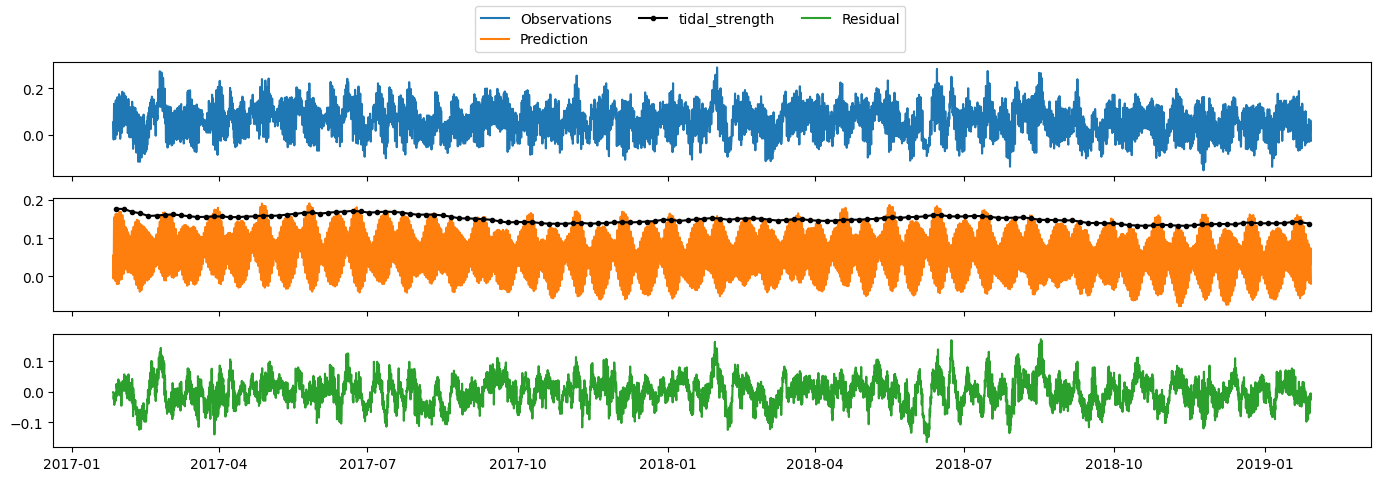

In [35]:
fig, (ax0, ax1, ax2) = plt.subplots(figsize=(17, 5), nrows=3, sharex=True)

ax0.plot(t, v, label="Observations", color="C0")
ax1.plot(t, tide.v, label="Prediction", color="C1")
ax1.plot(
    tidal_strength.index,
    seasonal_tidal_strength.to_numpy(),
    label="tidal_strength",
    color="k",
    marker=".",
    ls="solid",
)
ax2.plot(t, np.imag(residual.to_numpy()), label="Residual", color="C2")
fig.legend(ncol=3, loc="upper center");

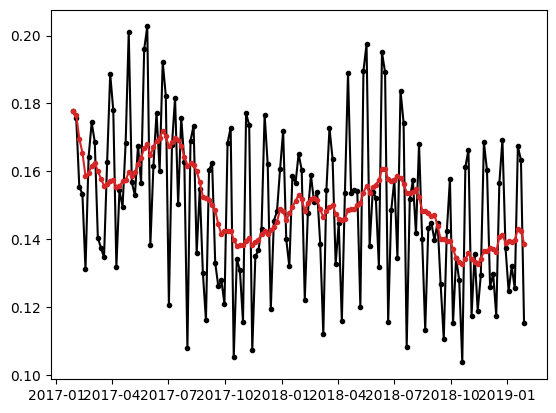

In [37]:
plt.plot(
    tidal_strength.index,
    tidal_strength.to_numpy(),
    label="tidal_strength",
    color="k",
    marker=".",
    ls="solid",
)
plt.plot(
    seasonal_tidal_strength.index,
    seasonal_tidal_strength.to_numpy(),
    label="tidal_strength",
    color="tab:red",
    marker=".",
    ls="solid",
)

In [38]:
seasonal_tidal_strength.to_csv(INTERIM_DATA_DIR / "seasonal_tidal_strength_at_C.csv")